# 01 · LEMIS: what the data looks like

Exploratory analysis of the **US Fish & Wildlife Service LEMIS data** (EcoHealth Alliance v1.1.0, 2000–2014), as published and before any alignment with CITES.

**Why this notebook exists.** Before deciding how LEMIS and CITES are aligned, we need to know what LEMIS actually contains: what one row is, what is missing, how the labels behave, and which codes and values need cleaning. Each finding ends in what LEMIS needs before training and what it means for alignment with CITES. Notebook 02 does the same for CITES, and notebook 03 compares the two.

**What it takes as given.** Only the publishers' rules for reading the file, recorded in [`DATA/USING_LEMIS_AND_CITES.md`](../../DATA/USING_LEMIS_AND_CITES.md) and cited below as *guide §x* (for example, which strings mean missing). Nothing here assumes an alignment rule. The rules for WildGuard's alignment were written afterwards from these findings, in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md).

Its findings feed report §3 (data) and §3.4 (schema alignment).

**Reading rules applied throughout** (guide §1.2): the strings `NA` and `non-standard value` are missing values, and exact duplicate rows are kept. The label is the guide's: *enforcement case* = refused (`action = R`) or disposition seized, abandoned or re-exported (`disposition ∈ {S, A, R}`).

In [1]:
import hashlib
import json

import matplotlib.pyplot as plt
import pandas as pd

import eda_setup as E
from eda_setup import config

E.style()
con = E.connect()


def Q(sql):
    return E.q(con, sql)


def pct(s):
    return (100 * s).round(2).astype(str) + "%"


codes = pd.read_csv(config.DATA_DIR / "reference" / "lemis_codes.csv", keep_default_na=False)
meaning = {f: g.set_index("code")["value"] for f, g in codes.groupby("field")}

## 1. File identity

The file must be v1.1.0 exactly: earlier releases contain different data (guide §1.1).

In [2]:
rec = json.loads(config.RAW_LEMIS_RECORD.read_text())
md5 = hashlib.md5()
with open(config.RAW_LEMIS, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 24), b""):
        md5.update(chunk)
cols = Q("DESCRIBE lemis_raw")["column_name"].tolist()
pd.Series({
    "Zenodo record / version": f"{rec['record']} / v{rec['version']} ({rec['published']})",
    "bytes": f"{config.RAW_LEMIS.stat().st_size:,}",
    "MD5 matches Zenodo": md5.hexdigest() == rec["md5"],
    "rows": f"{Q('SELECT count(*) FROM lemis_raw').iat[0, 0]:,}",
    "columns": len(cols),
    "import_export values": Q("SELECT list(DISTINCT import_export) FROM lemis_raw").iat[0, 0],
    "shipment years": tuple(Q("SELECT min(year), max(year) FROM lemis").iloc[0]),
}, name="LEMIS").to_frame()

,LEMIS
Zenodo record / version,3565869 / v1.1.0 (2019-12-06)
bytes,"973,799,285"
MD5 matches Zenodo,True
rows,"5,512,706"
columns,28
import_export values,[I]
shipment years,"(2000, 2014)"


## 2. What one row is

One row is one **product line item**; `control_number` identifies the shipment it belongs to (guide §1.3).

In [3]:
Q("""SELECT count(*) AS line_items, count(DISTINCT control_number) AS shipments,
            round(count(*) / count(DISTINCT control_number), 2) AS line_items_per_shipment
     FROM lemis""")

,line_items,shipments,line_items_per_shipment
0,5512706,2088676,2.64


In [4]:
Q("""WITH s AS (SELECT control_number, count(*) AS n FROM lemis GROUP BY 1)
     SELECT CASE WHEN n = 1 THEN '1' WHEN n <= 5 THEN '2-5' WHEN n <= 20 THEN '6-20'
                 WHEN n <= 100 THEN '21-100' ELSE 'over 100' END AS line_items_in_shipment,
            count(*) AS shipments, sum(n) AS line_items
     FROM s GROUP BY 1 ORDER BY min(n)""").pipe(E.share, "shipments", "share of shipments")

,line_items_in_shipment,shipments,line_items,share of shipments
0,1,1266700,"1,266,700",60.65%
1,2-5,630763,"1,798,430",30.2%
2,6-20,164563,"1,564,413",7.88%
3,21-100,26333,"837,801",1.26%
4,over 100,317,"45,362",0.02%


The guide says shipment-level fields are shared by all of a shipment's rows. If so, a shipment's rows must stay together in any train/test split.

In [5]:
Q("""WITH s AS (
       SELECT control_number,
              count(DISTINCT country_imp_exp) AS exporter, count(DISTINCT shipment_date) AS date,
              count(DISTINCT port) AS port, count(DISTINCT us_co) AS us_co,
              count(DISTINCT foreign_co) AS foreign_co
       FROM lemis_raw GROUP BY 1)
     SELECT count(*) FILTER (WHERE exporter > 1) AS exporter,
            count(*) FILTER (WHERE date > 1) AS shipment_date,
            count(*) FILTER (WHERE port > 1) AS port,
            count(*) FILTER (WHERE us_co > 1) AS us_co,
            count(*) FILTER (WHERE foreign_co > 1) AS foreign_co
     FROM s""").rename(index={0: "shipments where the field varies"})

,exporter,shipment_date,port,us_co,foreign_co
shipments where the field varies,0,0,0,0,0


**Exact duplicates.** EcoHealth removed near-duplicates but kept exact duplicates on purpose, because they can be real (guide §1.2).

In [6]:
dups = Q("""SELECT (SELECT count(*) FROM lemis_raw)
                   - (SELECT count(*) FROM (SELECT DISTINCT * FROM lemis_raw)) AS n""").iat[0, 0]
print(f"Exact duplicate rows beyond the first copy: {dups:,} ({dups / 5_512_706:.2%} of rows)")
Q("""SELECT control_number, description, quantity, unit, count(*) AS copies
     FROM lemis_raw WHERE control_number = '2000732392' GROUP BY ALL""")

Exact duplicate rows beyond the first copy: 153,485 (2.78% of rows)


,control_number,description,quantity,unit,copies
0,2000732392,GAR,2,NO,3
1,2000732392,GAR,5,NO,2
2,2000732392,GAR,3,NO,2
3,2000732392,GAR,1,NO,25
4,2000732392,GAR,4,NO,1
5,2000732392,GAR,8,NO,1


## 3. Coverage over time and the label

,year,line_items,shipments,cases,case_rate
0,2000,211782,95109,"4,559",2.15%
1,2001,256495,98070,"4,470",1.74%
2,2002,285830,110148,"4,552",1.59%
3,2003,321568,122098,"4,843",1.51%
4,2004,361368,139001,"5,558",1.54%
5,2005,403990,152485,"6,385",1.58%
6,2006,425513,163266,"7,198",1.69%
7,2007,429376,163363,"6,287",1.46%
8,2008,409937,155759,"7,464",1.82%
9,2009,385597,144597,"8,264",2.14%


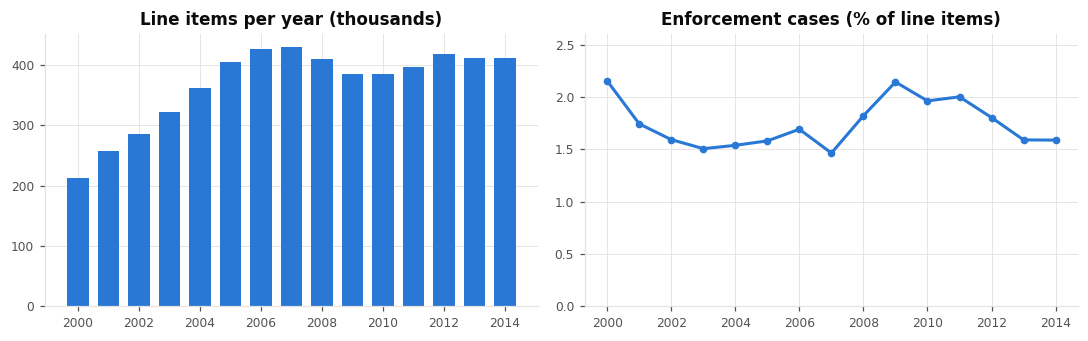

In [7]:
by_year = Q("""SELECT year, count(*) AS line_items, count(DISTINCT control_number) AS shipments,
                      sum(label) AS cases, avg(label) AS case_rate
               FROM lemis GROUP BY 1 ORDER BY 1""")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(by_year.year, by_year.line_items / 1e3, color=E.LEMIS_C, width=0.7)
ax[0].set_title("Line items per year (thousands)")
ax[1].plot(by_year.year, 100 * by_year.case_rate, color=E.LEMIS_C, marker="o", markersize=4)
ax[1].set_title("Enforcement cases (% of line items)")
ax[1].set_ylim(0, 2.6)
for a in ax:
    a.set_xticks(by_year.year[::2])
fig.tight_layout()
by_year.assign(case_rate=pct(by_year.case_rate))

## 4. Missing values

Two kinds of missing: `NA` (not recorded) and `non-standard value` (recorded, but EcoHealth could not interpret it; the original is in `cleaning_notes`).

In [8]:
agg = ", ".join(f"""count(*) FILTER (WHERE "{c}" = 'NA') AS "na|{c}",
                    count(*) FILTER (WHERE "{c}" = 'non-standard value') AS "ns|{c}" """
                for c in cols)
m = Q(f"SELECT {agg} FROM lemis_raw").T[0]
miss = pd.DataFrame({"NA": m[[f"na|{c}" for c in cols]].values,
                     "non-standard value": m[[f"ns|{c}" for c in cols]].values}, index=cols)
miss["missing share"] = pct((miss["NA"] + miss["non-standard value"]) / 5_512_706)
miss[(miss["NA"] + miss["non-standard value"]) > 0].sort_values("NA", ascending=False)

,NA,non-standard value,missing share
cleaning_notes,5375471,0,97.51%
subspecies,5265227,0,95.51%
specific_name,1944026,0,35.26%
value,1890969,0,34.3%
us_co,977359,0,17.73%
generic_name,410162,0,7.44%
class,403596,0,7.32%
genus,381054,0,6.91%
species,381054,0,6.91%
foreign_co,377664,0,6.85%


## 5. Labels: what the inspectors did

`action` and `disposition` are two separate fields, and the letter `R` means **refused** in `action` but **re-exported** in `disposition` (guide §1.3). Raw combinations:

In [9]:
Q("""SELECT action, disposition, count(*) AS line_items FROM lemis_raw
     GROUP BY ALL ORDER BY line_items DESC""")

,action,disposition,line_items
0,C,C,5417030
1,R,S,53028
2,R,A,22257
3,R,R,18212
4,R,C,2075
5,R,NA,39
6,R,non-standard value,29
7,C,R,23
8,C,non-standard value,10
9,C,S,2


In [10]:
cases = Q("""SELECT CASE disposition WHEN 'S' THEN 'seized' WHEN 'A' THEN 'abandoned'
                                     WHEN 'R' THEN 're-exported'
                                     ELSE 'refused, other or missing disposition' END AS outcome,
                    count(*) AS line_items
             FROM lemis WHERE label = 1 GROUP BY 1 ORDER BY 2 DESC""")
print(f"Enforcement cases: {cases.line_items.sum():,} of 5,512,706 line items "
      f"({cases.line_items.sum() / 5_512_706:.2%})")
cases.pipe(E.share, "line_items", "share of cases")

Enforcement cases: 95,665 of 5,512,706 line items (1.74%)


,outcome,line_items,share of cases
0,seized,53030,55.43%
1,abandoned,22257,23.27%
2,re-exported,18235,19.06%
3,"refused, other or missing disposition",2143,2.24%


Are labels a property of the line item or of the shipment?

In [11]:
Q("""WITH s AS (SELECT control_number, count(*) AS n, avg(label) AS r FROM lemis GROUP BY 1)
     SELECT count(*) FILTER (WHERE n > 1) AS multi_item_shipments,
            count(*) FILTER (WHERE n > 1 AND r > 0 AND r < 1) AS with_mixed_outcomes,
            round(100 * count(*) FILTER (WHERE n > 1 AND r > 0 AND r < 1)
                  / count(*) FILTER (WHERE n > 1), 2) AS mixed_pct
     FROM s""")

,multi_item_shipments,with_mixed_outcomes,mixed_pct
0,821976,8167,0.99


## 6. Declared value

CITES records no value (its columns are listed in guide §2.1), so `value` could only ever inform a LEMIS-only model. Its coverage by year decides whether even that is possible (guide §1.3).

,missing,zero,positive
year,,,
2000,0.0%,12.65%,87.35%
2001,0.0%,10.79%,89.21%
2002,0.0%,9.49%,90.51%
2003,0.0%,10.02%,89.98%
2004,0.0%,10.16%,89.84%
2005,0.0%,9.4%,90.6%
2006,0.0%,11.67%,88.33%
2007,0.0%,11.42%,88.58%
2008,100.0%,0.0%,0.0%


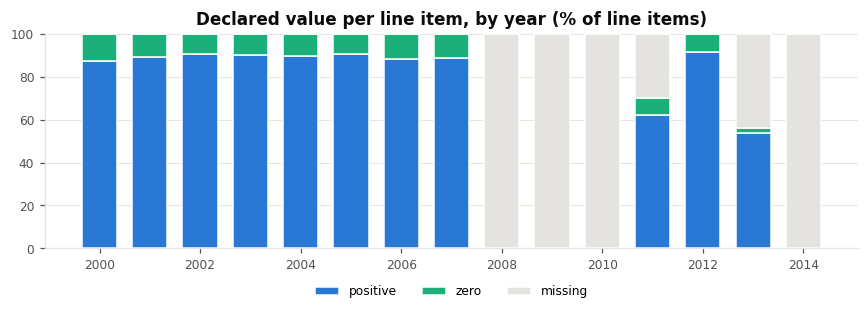

In [12]:
val = Q("""SELECT year, count(*) FILTER (WHERE value IS NULL) AS missing,
                  count(*) FILTER (WHERE value = 0) AS zero,
                  count(*) FILTER (WHERE value > 0) AS positive
           FROM lemis GROUP BY 1 ORDER BY 1""").set_index("year")
val_pct = val.div(val.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 3))
bottom = 0
for col, c in [("positive", E.LEMIS_C), ("zero", E.THIRD_C), ("missing", E.GRID)]:
    ax.bar(val_pct.index, 100 * val_pct[col], bottom=bottom, color=c, width=0.7,
           edgecolor="white", linewidth=1, label=col)
    bottom = bottom + 100 * val_pct[col]
ax.set_title("Declared value per line item, by year (% of line items)")
ax.set_xticks(val_pct.index[::2])
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
val_pct.apply(pct)

A zero value is a declaration; a missing value is not. Kept apart, among the years where value was recorded:

In [13]:
Q("""SELECT CASE label WHEN 1 THEN 'enforcement case' ELSE 'cleared' END AS outcome,
            count(*) AS line_items,
            round(100 * avg((value IS NULL)::INT), 1) AS pct_missing,
            round(100 * avg(coalesce(value = 0, false)::INT), 1) AS pct_zero_of_all,
            round(100 * avg((value = 0)::INT), 1) AS pct_zero_of_recorded
     FROM lemis WHERE year NOT IN (2008, 2009, 2010, 2014) GROUP BY 1""")

,outcome,line_items,pct_missing,pct_zero_of_all,pct_zero_of_recorded
0,cleared,3854290,7.6,9.1,9.8
1,enforcement case,65836,8.3,22.1,24.1


## 7. Codes and vocabularies

**Are all codes valid?** Each coded field against the USFWS code list (`DATA/reference/lemis_codes.csv`), ignoring missing values.

In [14]:
checks = {"description": "description", "unit": "unit", "purpose": "purpose", "source": "source",
          "action": "action", "disposition": "disposition", "country_origin": "country",
          "country_imp_exp": "country", "port": "port"}
rows = []
for col, field in checks.items():
    vc = Q(f"SELECT {col} AS code, count(*) AS n FROM lemis WHERE {col} IS NOT NULL GROUP BY 1")
    bad = vc[~vc.code.isin(meaning[field].index)].sort_values("n", ascending=False)
    rows.append({"field": col, "codes in list": len(meaning[field]), "codes used": len(vc),
                 "rows with a code not in the list": int(bad.n.sum()),
                 "examples": ", ".join(f"{c} ({n:,})" for c, n in bad.values[:6]) or "-"})
pd.DataFrame(rows).set_index("field")

,codes in list,codes used,rows with a code not in the list,examples
field,,,,
description,94,92,0,-
unit,12,12,0,-
purpose,12,12,0,-
source,9,9,0,-
action,2,2,0,-
disposition,4,4,0,-
country_origin,242,251,977,"CW (465), PR (151), VI (143), GU (77), CS (29)..."
country_imp_exp,242,256,1219,"CW (521), MP (187), VI (156), PR (128), GU (68..."
port,72,72,0,-


**Purpose and source**, with the enforcement rate in each group. Codes are LEMIS's. Whether CITES uses the same codes with the same meanings is tested in notebook 03.

In [15]:
def profile(col, field=None, top=None, min_rows=0):
    df = Q(f"""SELECT {col} AS code, count(*) AS line_items, sum(label) AS cases,
                      avg(label) AS case_rate
               FROM lemis GROUP BY 1 HAVING count(*) >= {min_rows} ORDER BY 2 DESC""")
    if field:
        df.insert(1, "meaning", df.code.map(meaning[field]))
    df["share of line items"] = pct(df.line_items / 5_512_706)
    df["share of cases"] = pct(df.cases / 95_665)
    df["case_rate"] = pct(df.case_rate)
    return df.head(top) if top else df

profile("purpose", "purpose")

,code,meaning,line_items,cases,case_rate,share of line items,share of cases
0,T,Commercial,4107450,"40,082",0.98%,74.51%,41.9%
1,H,Hunting Trophies,971201,"5,322",0.55%,17.62%,5.56%
2,P,Personal,186345,"47,469",25.47%,3.38%,49.62%
3,S,Scientific,142381,"1,707",1.2%,2.58%,1.78%
4,E,Educational,50824,174,0.34%,0.92%,0.18%
5,Z,Zoos,16313,61,0.37%,0.3%,0.06%
6,M,Biomedical research,15570,281,1.8%,0.28%,0.29%
7,None,NaN,14875,482,3.24%,0.27%,0.5%
8,Q,Circuses/traveling exhibitions,4845,63,1.3%,0.09%,0.07%
9,B,Breeding in captivity or artificial propagation,2006,8,0.4%,0.04%,0.01%


In [16]:
profile("source", "source")

,code,meaning,line_items,cases,case_rate,share of line items,share of cases
0,W,Specimens taken from the wild,4301115,"75,827",1.76%,78.02%,79.26%
1,C,"Animals bred in captivity, parts and derivatives",811618,"4,510",0.56%,14.72%,4.71%
2,R,Specimens originating from a ranching operation,229471,971,0.42%,4.16%,1.02%
3,F,"Animals born in captivity, Resolution conf. 10.16",107475,650,0.6%,1.95%,0.68%
4,U,Source unknown (must be justified),38269,"9,800",25.61%,0.69%,10.24%
5,P,Pre-convention,14291,503,3.52%,0.26%,0.53%
6,None,NaN,5418,"2,114",39.02%,0.1%,2.21%
7,D,Commercially bred,3213,150,4.67%,0.06%,0.16%
8,I,Confiscated or seized specimen,1411,"1,052",74.56%,0.03%,1.1%
9,A,"Plants that are artificially propagated, parts...",425,88,20.71%,0.01%,0.09%


**Product form** (`description`, 94 codes). The 20 most common, then the 15 with the highest enforcement rate among codes with at least 1,000 line items:

In [17]:
profile("description", "description", top=20)

,code,meaning,line_items,cases,case_rate,share of line items,share of cases
0,LIV,Live specimens (live animals or plants),1608115,"8,336",0.52%,29.17%,8.71%
1,TRO,Trophy (all the parts of one animal),918139,"4,646",0.51%,16.65%,4.86%
2,SPR,Shell product (mollusc or turtle),520033,"3,251",0.63%,9.43%,3.4%
3,LPS,Leather product (small manufactured including ...,375528,"10,201",2.72%,6.81%,10.66%
4,JWL,Jewelry (other than ivory jewelry),338280,"4,215",1.25%,6.14%,4.41%
5,GAR,Garment (excluding shoe or trim),222106,"1,330",0.6%,4.03%,1.39%
6,SHO,Shoe (including boots),220574,"6,073",2.75%,4.0%,6.35%
7,TRI,"Trim (shoe, garment, or decorative)",200650,"1,781",0.89%,3.64%,1.86%
8,SPE,Specimen (scientific or museum),159629,"1,977",1.24%,2.9%,2.07%
9,MEA,Meat,155636,"6,256",4.02%,2.82%,6.54%


In [18]:
prod = profile("description", "description", min_rows=1000)
prod.assign(r=prod.cases / prod.line_items).sort_values("r", ascending=False).drop(columns="r").head(15)

,code,meaning,line_items,cases,case_rate,share of line items,share of cases
27,MED,Medicinal part or product,10649,"7,542",70.82%,0.19%,7.88%
44,OIL,Oil,1234,533,43.19%,0.02%,0.56%
46,CLA,Claw (including talon),1166,353,30.27%,0.02%,0.37%
36,CAV,Caviar (unfertilized dead processed sturgeon o...,3770,"1,112",29.5%,0.07%,1.16%
40,FOO,Foot,2511,562,22.38%,0.05%,0.59%
47,DEA,Dead specimen (live specimen that died during ...,1055,235,22.27%,0.02%,0.25%
34,BON,"Bones (including jaws, but not skulls)",3794,745,19.64%,0.07%,0.78%
39,POW,Powder,2664,496,18.62%,0.05%,0.52%
25,EGG,Egg (whole dead or blown excluding caviar),12395,"2,121",17.11%,0.22%,2.22%
31,TEE,Teeth (excluding tusk),5634,759,13.47%,0.1%,0.79%


**Units.** `MT` is metres, not metric tonnes (guide §1.3). Quantities in different units can never be compared.

In [19]:
Q("""SELECT unit, count(*) AS line_items,
            count(*) FILTER (WHERE quantity = 0) AS zero_qty,
            count(*) FILTER (WHERE quantity IS NULL) AS missing_qty,
            quantile_cont(quantity, 0.5) AS median, quantile_cont(quantity, 0.9) AS p90,
            quantile_cont(quantity, 0.99) AS p99, max(quantity) AS max
     FROM lemis GROUP BY 1 ORDER BY 2 DESC""").assign(
    meaning=lambda d: d.unit.map(meaning["unit"]))

,unit,line_items,zero_qty,missing_qty,median,p90,p99,max,meaning
0,NO,5211366,1571,0,10,"1,200",3.582e+04,"108,000,000",Number of Specimens
1,KG,270196,10139,0,96,"14,515","24,003","151,331,000",Kilograms
2,GM,18350,507,0,200,"3,346",3.056e+05,"38,640,000",Grams
3,ML,8608,332,0,24,276.3,"2,500","259,340",Milliliters
4,M2,1373,30,0,47,892,"8,500","675,219",Square Meters
5,LT,1086,21,0,130,"17,765",7.768e+04,"309,067",Liters
6,MT,837,11,0,57,"1,122",2.425e+04,"111,683",Meters
7,MG,482,25,0,188,1.469e+04,1.654e+06,"4,680,000",Milligrams
8,CM,151,0,0,50,"1,300","92,000","176,970",Centimeters
9,C2,90,0,0,123.5,6.509e+05,3.781e+06,"4,351,578",Square Centimeters


Quantities are heavy-tailed even within one unit, so any quantity feature has to be on a log scale and judged relative to comparable records.

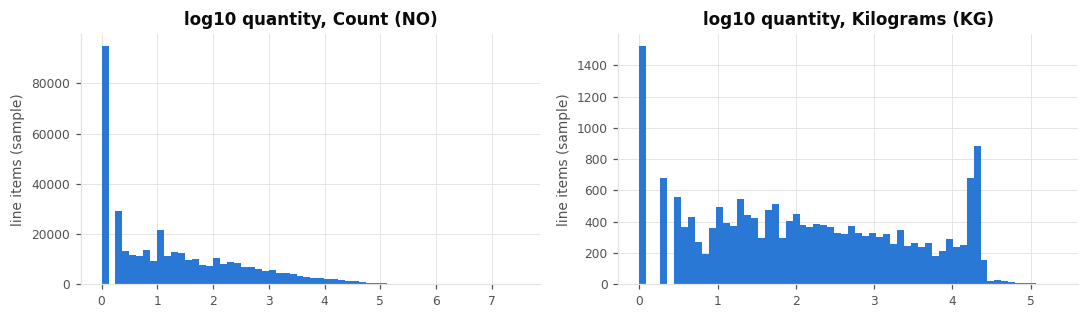

In [20]:
qty = Q("""SELECT unit, log10(quantity) AS lq FROM lemis
           WHERE unit IN ('NO', 'KG') AND quantity > 0 USING SAMPLE 400000""")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, u, title in [(ax[0], "NO", "Count (NO)"), (ax[1], "KG", "Kilograms (KG)")]:
    a.hist(qty.lq[qty.unit == u], bins=60, color=E.LEMIS_C)
    a.set_title(f"log10 quantity, {title}")
    a.set_ylabel("line items (sample)")
fig.tight_layout()

## 8. Taxonomy

In [21]:
Q("""SELECT count(*) FILTER (WHERE class IS NULL) AS no_class,
            count(*) FILTER (WHERE genus IS NULL) AS no_genus,
            count(*) FILTER (WHERE species = 'sp.') AS species_sp,
            count(DISTINCT genus) AS distinct_genus,
            count(DISTINCT genus || ' ' || species) FILTER (WHERE species <> 'sp.') AS distinct_species
     FROM lemis""").rename(index={0: "line items / names"})

,no_class,no_genus,species_sp,distinct_genus,distinct_species
line items / names,403596,381054,813383,6506,13052


Classes (assigned by EcoHealth from Catalogue of Life, guide §1.3), with the USFWS `taxa` grouping. Notebook 03 compares the class names with CITES's:

In [22]:
Q("""SELECT coalesce(class, '(none)') AS class, list(DISTINCT taxa ORDER BY taxa) AS taxa,
            count(*) AS line_items, round(100 * avg(label), 2) AS case_rate_pct
     FROM lemis GROUP BY 1 ORDER BY 3 DESC LIMIT 25""")

,class,taxa,line_items,case_rate_pct
0,Mammalia,[mammal],1589968,1.65
1,Reptilia,[reptile],724655,3.59
2,Anthozoa,[coral],681963,1.34
3,Bivalvia,[shell],523215,0.77
4,(none),"[coral, crustacean, fish, other, plant, shell,...",403596,1.12
5,Actinopterygii,[fish],391508,1.24
6,Aves,[bird],330921,3.09
7,Gastropoda,[shell],301777,1.26
8,Insecta,[insect],169620,0.96
9,Malacostraca,[crustacean],115725,0.16


Line items with no class: what are they?

In [23]:
Q("""SELECT taxa, genus, count(*) AS line_items FROM lemis WHERE class IS NULL
     GROUP BY ALL ORDER BY 3 DESC LIMIT 15""")

,taxa,genus,line_items
0,shell,None,186684
1,other,Other live inverts,103206
2,None,None,35299
3,other,Non-CITES entry,21549
4,crustacean,Non-CITES entry,19273
5,fish,Non-CITES entry,17185
6,fish,None,11745
7,shell,Non-CITES entry,4871
8,other,None,1492
9,coral,Non-CITES entry,976


`genus` is "genus **or higher-level taxonomic name**" (guide §1.3). Values that are clearly not genera (family names end in *-idae*, orders in *-formes* or are well-known order names):

In [24]:
Q("""SELECT genus, class, count(*) AS line_items FROM lemis
     WHERE genus SIMILAR TO '.*(idae|iformes|inae)' OR genus IN ('Scleractinia', 'Cetacea',
           'Testudines', 'Squamata', 'Psittaciformes', 'Antipatharia', 'Stylasteridae')
     GROUP BY ALL ORDER BY 3 DESC LIMIT 15""")

,genus,class,line_items
0,Scleractinia,Anthozoa,45922
1,Cheloniidae,Reptilia,4243
2,Anatidae,Aves,3067
3,Elephantidae,Mammalia,2397
4,Crocodylidae,Reptilia,903
5,Cetacea,Mammalia,849
6,Acipenseriformes,Actinopterygii,661
7,Cervidae,Mammalia,628
8,Tridacnidae,Bivalvia,628
9,Struthionidae,Aves,513


Notebook 03 counts these properly by matching LEMIS `genus` against the order, family and class names CITES uses.

## 9. Countries

Codes are mostly ISO-3166 alpha-2, plus USFWS codes (guide §1.3). The non-ISO ones:

In [25]:
Q("""WITH c AS (SELECT 'exporter' AS role, country_imp_exp AS code FROM lemis
               UNION ALL SELECT 'origin', country_origin FROM lemis)
     SELECT code, count(*) FILTER (WHERE role = 'exporter') AS as_exporter,
            count(*) FILTER (WHERE role = 'origin') AS as_origin
     FROM c WHERE code IN ('XX', 'VS', 'ZZ', 'ZR', 'TP', 'AN') OR code IS NULL
     GROUP BY 1 ORDER BY 3 DESC""").assign(meaning=lambda d: d.code.map(meaning["country"]))

,code,as_exporter,as_origin,meaning
0,XX,80068,152781,Unknown
1,VS,52,17044,Various
2,ZZ,800,1455,High Seas
3,AN,1023,620,Curacao / Netherlands Antilles
4,ZR,384,238,Zaire
5,None,51,48,NaN
6,TP,5,20,NaN


In [26]:
Q("""SELECT count(DISTINCT country_imp_exp) AS exporters, count(DISTINCT country_origin) AS origins,
            round(100 * avg((country_origin = 'US')::INT), 2) AS pct_origin_US,
            round(100 * avg((country_origin <> country_imp_exp)::INT), 2) AS pct_origin_not_exporter
     FROM lemis""")

,exporters,origins,pct_origin_US,pct_origin_not_exporter
0,256,251,5.92,32.62


## 10. Fields only LEMIS has

`value`, `port`, month and the company names have no CITES counterpart (CITES's columns: guide §2.1). The company fields are often redacted under FOIA.

In [27]:
Q("""SELECT count(DISTINCT port) AS ports,
            round(100 * avg((us_co = 'EXEMPTIONS 6 AND 7(C)')::INT), 2) AS pct_us_co_redacted,
            round(100 * avg((us_co = 'NA')::INT), 2) AS pct_us_co_missing,
            round(100 * avg((foreign_co = 'EXEMPTIONS 6 AND 7(C)')::INT), 2) AS pct_foreign_co_redacted,
            round(100 * avg((foreign_co = 'NA')::INT), 2) AS pct_foreign_co_missing
     FROM lemis_raw""")

,ports,pct_us_co_redacted,pct_us_co_missing,pct_foreign_co_redacted,pct_foreign_co_missing
0,73,2.2,17.73,0.51,6.85


## Findings and what they imply

The counts the publishers state for LEMIS (guide §1) were reproduced: file identity, shipments, labels, value coverage, country codes and company redaction. The findings below are what the data adds. For each one, the table gives what **LEMIS itself needs** before training, and what it **implies for alignment** with CITES (worked out in notebook 03). The rules that follow are recorded in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md), which cites each finding by number.

| # | Finding | Preprocessing LEMIS needs | Implication for alignment | Report |
|---|---|---|---|---|
| L1 | 5,512,706 line items in 2,088,676 shipments; 61% of shipments have one line item. Exporter, date, port and companies never vary within a shipment | Keep a shipment's line items together in any train/test split; evaluate at shipment level as well as line-item level | The line item is the unit both datasets share. CITES's closest equivalent of a shipment is the export permit (notebook 02 C12), which can group line items into consignments (notebook 05); LEMIS shipments and CITES permits cannot be linked to each other | §3.1, §6.1 |
| L2 | 153,485 exact duplicate rows (2.8%), kept on purpose by EcoHealth (e.g. 25 identically declared garments) | Do not de-duplicate | None | §3.1 |
| L3 | `NA` and `non-standard value` are both missing; `non-standard value` mainly affects `purpose` (12,794 rows) and `source` (667) | Read both as missing; map missing purpose and source to "unknown"; never drop the row | CITES needs the same "unknown" category for its own missing codes (C12) | §3.4 |
| L4 | Label: 95,665 enforcement cases (1.74%): 55% seized, 23% abandoned, 19% re-exported, 2% refused with another disposition. `R` means refused in `action` but re-exported in `disposition` | Define the label from both fields (`action = R` or `disposition` ∈ {S, A, R}); report the outcome mix; use ranking metrics, since accuracy is uninformative at this base rate | The label exists only in LEMIS; it is what the model carries over to CITES | §3.2 |
| L5 | Case rate stable at 1.5–2.2% a year; only 1.0% of multi-item shipments have mixed outcomes | A temporal split by shipment year is meaningful; labels behave as shipment-level | None | §3.2 |
| L6 | Declared value missing for all of 2008–2010 and 2014, and 30% / 44% of 2011 / 2013. Where recorded, zero values are 2.5× as common among enforcement cases (24.1% vs 9.8%) | Keep `NA` and 0 apart; a value feature can only use the years where value was recorded, which excludes the test year 2014 | CITES records no value, so value cannot be a transfer feature | §3.3, §3.4 |
| L7 | Personal imports are 3.4% of line items but 49.6% of cases (case rate 25.5%); commercial: 74.5% of line items, 41.9% of cases (0.98%) | Report results on a commercial-only subset as well as overall | The label is dominated by a traveller-luggage pattern; whether CITES contains it is checked in notebooks 02 (C6) and 03 (X10) | §3.3 |
| L8 | Source `U` unknown (25.6%) and `I` confiscated (74.6%) have very high case rates; LEMIS writes pre-Convention as `P` | None | Source is a strong signal, so its codes must mean the same thing in both datasets (tested in notebook 03, X3) | §3.3, §3.4 |
| L9 | Product form carries signal: medicinal products 70.8%, oil 43.2%, caviar 29.5%, ivory carvings 10.1% vs live animals 0.5% | Keep product form at a grain that separates these (worked vs raw; ivory, horn and bone apart) | Shared product groups must preserve that grain (X5) | §3.3, §3.4 |
| L10 | Quantities are heavy-tailed within each unit (count: median 10, p99 ≈ 36,000); 12 unit codes plus 89 rows with none, `MT` = metres | Log-transform; compare quantities only within one unit and one peer group | LEMIS unit codes must map onto the same canonical units as CITES's (X4) | §3.4 |
| L11 | 7.3% of rows have no class: shells without a genus, and placeholder "genera" such as *Non-CITES entry* and *Other live inverts*. `genus` also holds higher taxa (*Scleractinia* 45,922 rows, *Cheloniidae*, *Elephantidae* …). Some plants (*Magnoliopsida*) are included | Treat placeholder genera as unknown; decide whether rows without a class stay in the training population | Higher taxa need one convention shared with CITES (X7); the training population is decided with the CITES scope in view (X2) | §3.4 |
| L12 | Country codes are ISO-3166 plus `XX` unknown (152,781 origins), `VS` various (17,044 origins), `ZZ`, `ZR`, `TP`, `AN`; US territories (PR, VI, GU, MP) appear although not in the USFWS list | Treat `XX` and `non-standard value` as unknown | The non-ISO codes need CITES equivalents (X9) | §3.4 |
| L13 | `value`, `port`, month and companies have no CITES counterpart; company names are 18% / 7% missing and partly FOIA-redacted | Usable only by a LEMIS-only comparison model | Keep them out of the transfer feature set (X12) | §3.4 |

### What LEMIS needs before training

1. Check the file is v1.1.0 (MD5, guide §1.1).
2. Read `NA` and `non-standard value` as missing; missing purpose and source become "unknown" (L3).
3. Keep exact duplicates (L2).
4. Label = `action = R` or `disposition` ∈ {S, A, R} (L4).
5. Split by shipment year, keeping each shipment's line items together; evaluate per line item and per shipment (L1, L5).
6. Treat placeholder genera and `XX` as unknown (L11, L12).
7. Log-transform quantities and compare them only within a unit (L10).
8. Use `value` only in a LEMIS-only model, only in the years it was recorded, with `NA` and 0 kept apart (L6).

The steps that depend on CITES (code, unit, product, taxonomy and country mappings) are worked out in notebook 03.